In [21]:
import pandas as pd
import matplotlib.pyplot as mp
import seaborn as ab
import os

os.chdir("D:/gus6e/Documents")

from sklearn.cluster import KMeans

dataset = pd.read_csv("iris.csv")
dataset.head()

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


In [22]:
fields = dataset.iloc[:,[0,1,2,3]].values
print(fields)

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]
 [5.4 3.7 1.5 0.2]
 [4.8 3.4 1.6 0.2]
 [4.8 3.  1.4 0.1]
 [4.3 3.  1.1 0.1]
 [5.8 4.  1.2 0.2]
 [5.7 4.4 1.5 0.4]
 [5.4 3.9 1.3 0.4]
 [5.1 3.5 1.4 0.3]
 [5.7 3.8 1.7 0.3]
 [5.1 3.8 1.5 0.3]
 [5.4 3.4 1.7 0.2]
 [5.1 3.7 1.5 0.4]
 [4.6 3.6 1.  0.2]
 [5.1 3.3 1.7 0.5]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.  3.4 1.6 0.4]
 [5.2 3.5 1.5 0.2]
 [5.2 3.4 1.4 0.2]
 [4.7 3.2 1.6 0.2]
 [4.8 3.1 1.6 0.2]
 [5.4 3.4 1.5 0.4]
 [5.2 4.1 1.5 0.1]
 [5.5 4.2 1.4 0.2]
 [4.9 3.1 1.5 0.2]
 [5.  3.2 1.2 0.2]
 [5.5 3.5 1.3 0.2]
 [4.9 3.6 1.4 0.1]
 [4.4 3.  1.3 0.2]
 [5.1 3.4 1.5 0.2]
 [5.  3.5 1.3 0.3]
 [4.5 2.3 1.3 0.3]
 [4.4 3.2 1.3 0.2]
 [5.  3.5 1.6 0.6]
 [5.1 3.8 1.9 0.4]
 [4.8 3.  1.4 0.3]
 [5.1 3.8 1.6 0.2]
 [4.6 3.2 1.4 0.2]
 [5.3 3.7 1.5 0.2]
 [5.  3.3 1.4 0.2]
 [7.  3.2 4.7 1.4]
 [6.4 3.2 4.5 1.5]
 [6.9 3.1 4.

In [23]:
import warnings
warnings.filterwarnings("ignore")

In [24]:
wcss = []
for index in range(1,11):
    kmeans = KMeans(n_clusters = index, init = "k-means++", random_state = 2)
    kmeans.fit(fields)

    wcss.append(kmeans.inertia_)

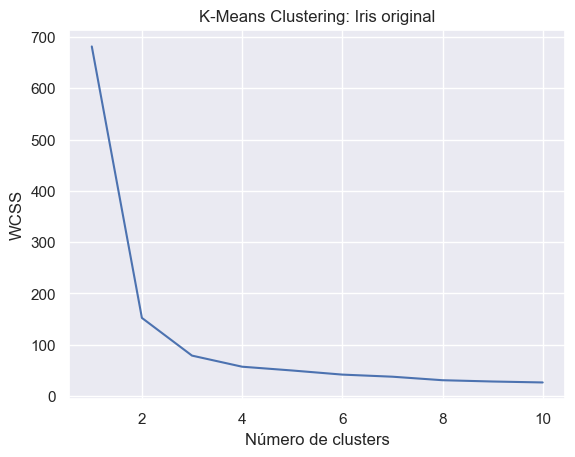

In [25]:
#Graficación del "Codo de Jambu"
ab.set()
mp.plot(range(1,11), wcss)
mp.title("K-Means Clustering: Iris original")
mp.xlabel("Número de clusters")
mp.ylabel("WCSS") #Weighted cluster sum of squares
mp.show()

In [26]:
kmeans = KMeans(n_clusters = 3, init = "k-means++", random_state = 42)
cluster_values = kmeans.fit_predict(fields)
print(cluster_values)
cluster_values_original = cluster_values.copy()

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 0 0 0 0 2 0 0 0 0
 0 0 2 2 0 0 0 0 2 0 2 0 2 0 0 2 2 0 0 0 0 0 2 0 0 0 0 2 0 0 0 2 0 0 0 2 0
 0 2]


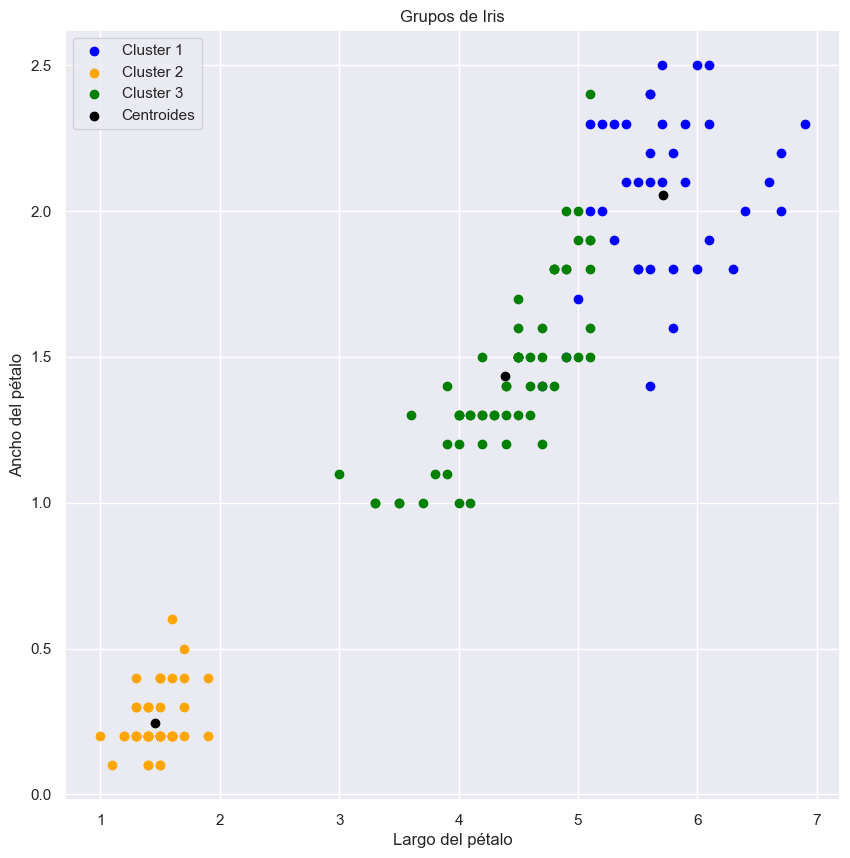

In [27]:
mp.figure(figsize = (10,10))
mp.scatter(fields[cluster_values==0,2], fields[cluster_values==0,3], c = "blue", label = "Cluster 1")
mp.scatter(fields[cluster_values==1,2], fields[cluster_values==1,3], c = "orange", label = "Cluster 2")
mp.scatter(fields[cluster_values==2,2], fields[cluster_values==2,3], c = "green", label = "Cluster 3")

mp.scatter(kmeans.cluster_centers_[:,2], kmeans.cluster_centers_[:,3], c = "black", label = "Centroides")

mp.title("Grupos de Iris")
mp.xlabel("Largo del pétalo")
mp.ylabel("Ancho del pétalo")
mp.legend()
mp.show()

In [28]:
# Criterio de Silueta ("Silhouette")
from sklearn import datasets
from sklearn.metrics import silhouette_score

In [29]:
X = dataset.iloc[:, [0,1,2,3]].to_numpy()
for j in range(2,12):
    kmeans = KMeans(n_clusters = j, random_state = 42)
    kmeans.fit_predict(X)
    #Calculamos el Score de Silueta
    score = silhouette_score(X,kmeans.labels_,metric = "euclidean")
    print("Score Silhouette:", "K =", j, "Score =", score)

Score Silhouette: K = 2 Score = 0.6810461692117465
Score Silhouette: K = 3 Score = 0.5511916046195927
Score Silhouette: K = 4 Score = 0.49764331793219296
Score Silhouette: K = 5 Score = 0.493080406719353
Score Silhouette: K = 6 Score = 0.3678464984712254
Score Silhouette: K = 7 Score = 0.3542978877198859
Score Silhouette: K = 8 Score = 0.3446797218056206
Score Silhouette: K = 9 Score = 0.3155887853389787
Score Silhouette: K = 10 Score = 0.30141437453251546
Score Silhouette: K = 11 Score = 0.2687356216412038


In [30]:
# Algoritmo KMeans aplicado a cuatro columnas de nuestra base original
# Bajo una transformación de PCA

fields2 = dataset.iloc[: , [0,1,2,3]].values
print(fields2)

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]
 [5.4 3.7 1.5 0.2]
 [4.8 3.4 1.6 0.2]
 [4.8 3.  1.4 0.1]
 [4.3 3.  1.1 0.1]
 [5.8 4.  1.2 0.2]
 [5.7 4.4 1.5 0.4]
 [5.4 3.9 1.3 0.4]
 [5.1 3.5 1.4 0.3]
 [5.7 3.8 1.7 0.3]
 [5.1 3.8 1.5 0.3]
 [5.4 3.4 1.7 0.2]
 [5.1 3.7 1.5 0.4]
 [4.6 3.6 1.  0.2]
 [5.1 3.3 1.7 0.5]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.  3.4 1.6 0.4]
 [5.2 3.5 1.5 0.2]
 [5.2 3.4 1.4 0.2]
 [4.7 3.2 1.6 0.2]
 [4.8 3.1 1.6 0.2]
 [5.4 3.4 1.5 0.4]
 [5.2 4.1 1.5 0.1]
 [5.5 4.2 1.4 0.2]
 [4.9 3.1 1.5 0.2]
 [5.  3.2 1.2 0.2]
 [5.5 3.5 1.3 0.2]
 [4.9 3.6 1.4 0.1]
 [4.4 3.  1.3 0.2]
 [5.1 3.4 1.5 0.2]
 [5.  3.5 1.3 0.3]
 [4.5 2.3 1.3 0.3]
 [4.4 3.2 1.3 0.2]
 [5.  3.5 1.6 0.6]
 [5.1 3.8 1.9 0.4]
 [4.8 3.  1.4 0.3]
 [5.1 3.8 1.6 0.2]
 [4.6 3.2 1.4 0.2]
 [5.3 3.7 1.5 0.2]
 [5.  3.3 1.4 0.2]
 [7.  3.2 4.7 1.4]
 [6.4 3.2 4.5 1.5]
 [6.9 3.1 4.

In [31]:
from sklearn import decomposition

pca = decomposition.PCA(n_components=2)
pca.fit(fields2)
fields2 = pca.transform(fields2)
fields2

array([[-2.68412563,  0.31939725],
       [-2.71414169, -0.17700123],
       [-2.88899057, -0.14494943],
       [-2.74534286, -0.31829898],
       [-2.72871654,  0.32675451],
       [-2.28085963,  0.74133045],
       [-2.82053775, -0.08946138],
       [-2.62614497,  0.16338496],
       [-2.88638273, -0.57831175],
       [-2.6727558 , -0.11377425],
       [-2.50694709,  0.6450689 ],
       [-2.61275523,  0.01472994],
       [-2.78610927, -0.235112  ],
       [-3.22380374, -0.51139459],
       [-2.64475039,  1.17876464],
       [-2.38603903,  1.33806233],
       [-2.62352788,  0.81067951],
       [-2.64829671,  0.31184914],
       [-2.19982032,  0.87283904],
       [-2.5879864 ,  0.51356031],
       [-2.31025622,  0.39134594],
       [-2.54370523,  0.43299606],
       [-3.21593942,  0.13346807],
       [-2.30273318,  0.09870885],
       [-2.35575405, -0.03728186],
       [-2.50666891, -0.14601688],
       [-2.46882007,  0.13095149],
       [-2.56231991,  0.36771886],
       [-2.63953472,

In [32]:
print("Varianza explicada por cada componente:", pca.explained_variance_ratio_)
print("Varianza total conservada:", pca.explained_variance_ratio_.sum())

Varianza explicada por cada componente: [0.92461872 0.05306648]
Varianza total conservada: 0.9776852063187922


In [33]:
wcss2 = []
for index in range(1,11):
    kmeans = KMeans(n_clusters = index, init = "k-means++", random_state = 2)
    kmeans.fit(fields2)

    wcss2.append(kmeans.inertia_)

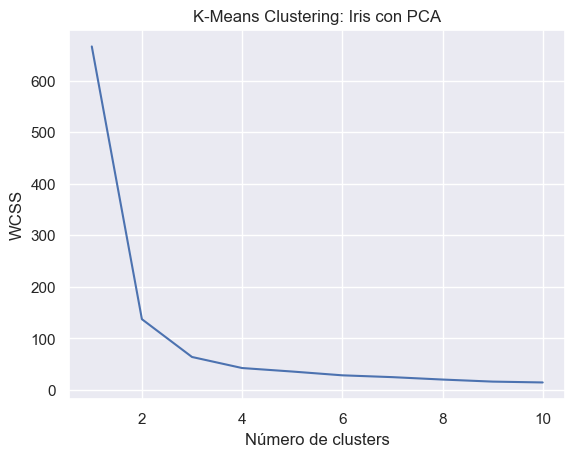

In [34]:
#Graficación del "Codo de Jambu"
ab.set()
mp.plot(range(1,11), wcss2)
mp.title("K-Means Clustering: Iris con PCA")
mp.xlabel("Número de clusters")
mp.ylabel("WCSS") #Weighted cluster sum of squares
mp.show()

In [35]:
kmeans = KMeans(n_clusters = 3, init = "k-means++", random_state = 42)
cluster_values = kmeans.fit_predict(fields2)
print(cluster_values)
cluster_values_pca = cluster_values.copy()

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 0 0 0 0 2 0 0 0 0
 0 0 2 2 0 0 0 0 2 0 2 0 2 0 0 2 2 0 0 0 0 0 2 0 0 0 0 2 0 0 0 2 0 0 0 2 0
 0 2]


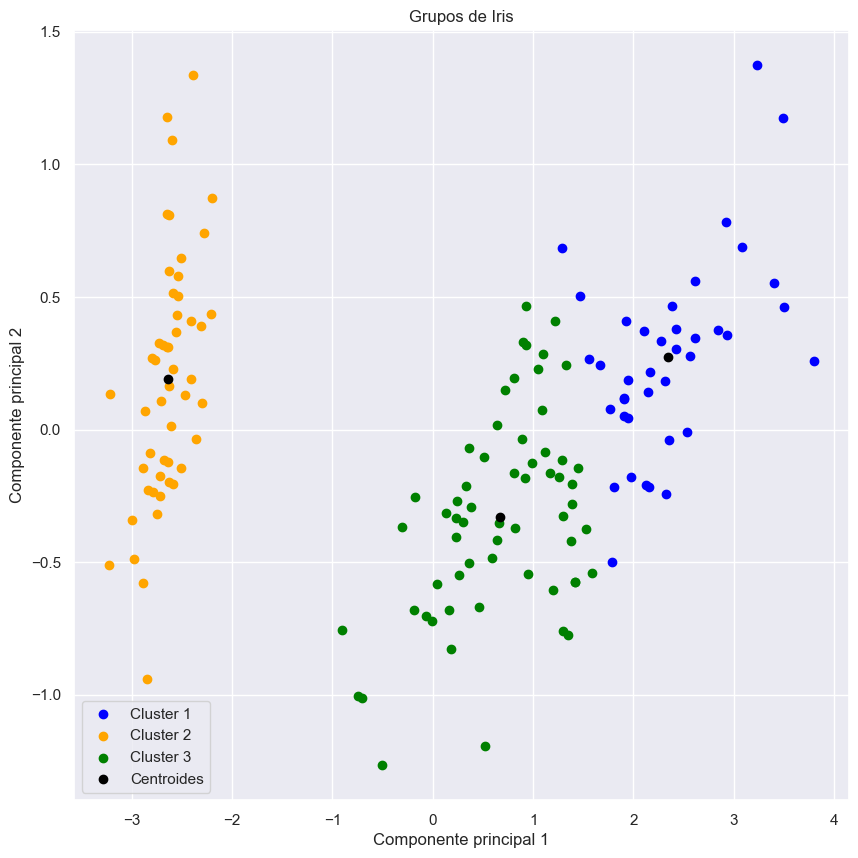

In [36]:
mp.figure(figsize = (10,10))
mp.scatter(fields2[cluster_values==0,0], fields2[cluster_values==0,1], c = "blue", label = "Cluster 1")
mp.scatter(fields2[cluster_values==1,0], fields2[cluster_values==1,1], c = "orange", label = "Cluster 2")
mp.scatter(fields2[cluster_values==2,0], fields2[cluster_values==2,1], c = "green", label = "Cluster 3")

mp.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], c = "black", label = "Centroides")

mp.title("Grupos de Iris")
mp.xlabel("Componente principal 1")
mp.ylabel("Componente principal 2")
mp.legend()
mp.show()

In [37]:
X = fields2
for j in range(2,12):
    kmeans = KMeans(n_clusters = j, random_state = 42)
    kmeans.fit_predict(X)
    #Calculamos el Score de Silueta
    score = silhouette_score(X,kmeans.labels_,metric = "euclidean")
    print("Score Silhouette:", "K =", j, "Score =", score)

Score Silhouette: K = 2 Score = 0.7056703225102109
Score Silhouette: K = 3 Score = 0.5976764219547989
Score Silhouette: K = 4 Score = 0.5577409232246782
Score Silhouette: K = 5 Score = 0.5100407194899204
Score Silhouette: K = 6 Score = 0.40319738737442684
Score Silhouette: K = 7 Score = 0.3868263997713609
Score Silhouette: K = 8 Score = 0.4407603324965402
Score Silhouette: K = 9 Score = 0.4020143876366364
Score Silhouette: K = 10 Score = 0.41588658017532526
Score Silhouette: K = 11 Score = 0.3994325519305243
